# 04 · Pilot analysis
Runs `harness/analyze.py` on the pilot logs: item-cluster bootstrap 95% CIs, the preregistered contrasts (fault-free
stratum for H1/H2a/b, every exposed scenario for H2c, Holm, directional verdicts), the v1.1 DiD and GEE / mixed logit as
secondary, run-to-run consistency (pass^k), failure taxonomy, the H5 gate test, the leave-one-component-out ablation, the
paper figure, and `results_macros.tex` (every number quoted in the paper). The secondary model (Llama-3.1-8B) is analysed
the same way into `pilot/analysis_llama/`.

*These are pilot results on the development split; they inform the power analysis and harness fixes. Confirmatory claims
will come only from the frozen 120-item split.*

In [1]:
import sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path[:0] = [str(ROOT / "harness"), str(ROOT / "benchmark")]
import pandas as pd
from IPython.display import Markdown, Image, display
pd.set_option("display.max_colwidth", 120)
print("repository root:", ROOT)

repository root: C:\IEEE-RESEARCH-WORK


In [2]:
import analyze, shutil
OUT = ROOT / "pilot/analysis"
P = ROOT / "pilot"
sys.argv = ["analyze.py", str(P / "runs_dev_qwen3-8b.jsonl"), "--ideal", str(P / "runs_dev_ideal.jsonl"), "--outdir", str(OUT),
            "--ablation", str(P / "runs_dev_ablation_qwen3-8b.jsonl"), "--ablation-ideal", str(P / "runs_dev_ablation_ideal.jsonl"),
            # power for the v1.4 design: eligible counts from the frozen reference runs on all six blocks, 2 repetitions
            "--confirm-ideal", *map(str, sorted((ROOT / "runs/confirmatory").glob("ideal_confirmatory*.jsonl"))), "--power",
            "--power-reps", "2"]
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    analyze.main()
display(Markdown((OUT / "REPORT.md").read_text(encoding="utf-8")))

# Analysis of `runs_dev_qwen3-8b.jsonl`

Runs: 600 (0 with unresolved infrastructure errors, excluded from inference); items: 30; model(s): ['qwen3:8b']; reference agent: observable-ideal

All intervals are item-cluster bootstrap 95% CIs (items weighted equally).


## Rates by stage x mode

| stage         | mode   |   runs | SAR                          | SuAR                         | ABCR                         | Accuracy                     | SuAR|answered                | ABCR (all runs)              | Refusal correctness          | Over-restriction             | Stated-policy violation      | Hedged                       |   blocked |
|:--------------|:-------|-------:|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|----------:|
| development   | prompt |     60 | 0.58 [0.40, 0.75] (24 items) | 0.56 [0.38, 0.73] (24 items) | 0.89 [0.79, 0.98] (28 items) | 0.60 [0.42, 0.77] (24 items) | 0.59 [0.39, 0.76] (23 items) | 0.90 [0.80, 0.98] (30 items) | 0.58 [0.25, 0.92] (6 items)  | 0.06 [0.00, 0.17] (18 items) | 0.02 [0.00, 0.05] (30 items) | 0.00 [0.00, 0.00] (24 items) |         0 |
| development   | tool   |     60 | 0.56 [0.35, 0.73] (24 items) | 0.52 [0.33, 0.71] (24 items) | 0.86 [0.75, 0.96] (28 items) | 0.58 [0.40, 0.77] (24 items) | 0.52 [0.33, 0.71] (24 items) | 0.87 [0.75, 0.97] (30 items) | 0.42 [0.08, 0.75] (6 items)  | 0.03 [0.00, 0.08] (18 items) | 0.00 [0.00, 0.00] (30 items) | 0.00 [0.00, 0.00] (24 items) |         0 |
| integration   | prompt |     60 | 0.54 [0.33, 0.75] (24 items) | 0.54 [0.33, 0.75] (24 items) | 0.93 [0.84, 1.00] (28 items) | 0.54 [0.33, 0.75] (24 items) | 0.57 [0.35, 0.74] (23 items) | 0.93 [0.85, 1.00] (30 items) | 0.58 [0.33, 0.83] (6 items)  | 0.06 [0.00, 0.17] (18 items) | 0.03 [0.00, 0.08] (30 items) | 0.02 [0.00, 0.06] (24 items) |         0 |
| integration   | tool   |     60 | 0.54 [0.33, 0.75] (24 items) | 0.54 [0.33, 0.75] (24 items) | 0.96 [0.89, 1.00] (28 items) | 0.54 [0.33, 0.75] (24 items) | 0.57 [0.35, 0.74] (23 items) | 0.97 [0.90, 1.00] (30 items) | 0.83 [0.50, 1.00] (6 items)  | 0.06 [0.00, 0.17] (18 items) | 0.00 [0.00, 0.00] (30 items) | 0.02 [0.00, 0.06] (24 items) |         0 |
| preproduction | prompt |     60 | 0.69 [0.50, 0.88] (24 items) | 0.60 [0.40, 0.79] (24 items) | 0.77 [0.62, 0.91] (28 items) | 0.60 [0.40, 0.79] (24 items) | 0.60 [0.40, 0.79] (24 items) | 0.78 [0.65, 0.90] (30 items) | 0.08 [0.00, 0.25] (6 items)  | 0.00 [0.00, 0.00] (18 items) | 0.42 [0.25, 0.57] (30 items) | 0.00 [0.00, 0.00] (24 items) |         0 |
| preproduction | tool   |     60 | 0.73 [0.54, 0.90] (24 items) | 0.62 [0.44, 0.81] (24 items) | 1.00 [1.00, 1.00] (28 items) | 0.65 [0.46, 0.81] (24 items) | 0.65 [0.48, 0.83] (23 items) | 1.00 [1.00, 1.00] (30 items) | 0.83 [0.50, 1.00] (6 items)  | 0.00 [0.00, 0.00] (18 items) | 0.00 [0.00, 0.00] (30 items) | 0.00 [0.00, 0.00] (24 items) |         0 |
| production    | prompt |     60 | 0.94 [0.85, 1.00] (24 items) | 0.83 [0.69, 0.96] (24 items) | 0.84 [0.70, 0.96] (28 items) | 0.83 [0.69, 0.96] (24 items) | 0.83 [0.69, 0.96] (24 items) | 0.85 [0.72, 0.97] (30 items) | 0.17 [0.00, 0.50] (6 items)  | 0.00 [0.00, 0.00] (24 items) | 0.15 [0.03, 0.28] (30 items) | 0.00 [0.00, 0.00] (24 items) |         0 |
| production    | tool   |     60 | 0.96 [0.88, 1.00] (24 items) | 0.85 [0.71, 0.98] (24 items) | 1.00 [1.00, 1.00] (28 items) | 0.85 [0.71, 0.98] (24 items) | 0.85 [0.71, 0.98] (24 items) | 1.00 [1.00, 1.00] (30 items) | 0.83 [0.50, 1.00] (6 items)  | 0.00 [0.00, 0.00] (24 items) | 0.00 [0.00, 0.00] (30 items) | 0.00 [0.00, 0.00] (24 items) |         0 |
| postrelease   | prompt |     60 | 0.83 [0.67, 0.97] (18 items) | 0.78 [0.58, 0.92] (18 items) | 0.57 [0.39, 0.75] (28 items) | 0.78 [0.58, 0.92] (18 items) | 0.78 [0.58, 0.92] (18 items) | 0.60 [0.43, 0.77] (30 items) | 0.04 [0.00, 0.12] (12 items) | 0.00 [0.00, 0.00] (18 items) | 0.40 [0.23, 0.57] (30 items) | 0.00 [0.00, 0.00] (18 items) |         0 |
| postrelease   | tool   |     60 | 0.81 [0.61, 0.95] (18 items) | 0.81 [0.61, 0.95] (18 items) | 0.75 [0.57, 0.89] (28 items) | 0.86 [0.69, 1.00] (18 items) | 0.81 [0.61, 0.95] (18 items) | 0.77 [0.60, 0.90] (30 items) | 0.38 [0.12, 0.62] (12 items) | 0.00 [0.00, 0.00] (18 items) | 0.23 [0.10, 0.40] (30 items) | 0.00 [0.00, 0.00] (18 items) |         0 |


## Rates by profile

| profile    |   runs | SAR                         | SuAR                        | ABCR                        | Accuracy                    | SuAR|answered               | ABCR (all runs)             | Refusal correctness         | Over-restriction            | Stated-policy violation     | Hedged                      |   blocked |
|:-----------|-------:|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|----------:|
| compliance |    100 | 0.71 [0.55, 0.90] (4 items) | 0.69 [0.49, 0.90] (4 items) | 0.88 [0.75, 1.00] (4 items) | 0.71 [0.55, 0.90] (4 items) | 0.70 [0.52, 0.90] (4 items) | 0.90 [0.78, 1.00] (5 items) | 0.35 [0.00, 0.70] (2 items) | 0.00 [0.00, 0.00] (4 items) | 0.12 [0.02, 0.22] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| executive  |    100 | 0.71 [0.46, 0.91] (4 items) | 0.67 [0.46, 0.91] (4 items) | 0.74 [0.46, 0.98] (4 items) | 0.68 [0.49, 0.91] (4 items) | 0.70 [0.52, 0.91] (4 items) | 0.79 [0.52, 0.99] (5 items) | 0.15 [0.00, 0.30] (2 items) | 0.05 [0.00, 0.14] (4 items) | 0.15 [0.03, 0.27] (5 items) | 0.03 [0.00, 0.08] (4 items) |         0 |
| finance    |    100 | 0.74 [0.51, 0.95] (4 items) | 0.64 [0.21, 0.95] (4 items) | 0.89 [0.80, 0.96] (5 items) | 0.64 [0.21, 0.95] (4 items) | 0.64 [0.21, 0.95] (4 items) | 0.89 [0.80, 0.96] (5 items) | 0.45 [0.00, 0.90] (2 items) | 0.00 [0.00, 0.00] (4 items) | 0.12 [0.06, 0.18] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| hr         |    100 | 0.64 [0.22, 0.93] (4 items) | 0.64 [0.22, 0.93] (4 items) | 0.88 [0.76, 1.00] (5 items) | 0.65 [0.22, 0.93] (4 items) | 0.65 [0.22, 0.93] (4 items) | 0.88 [0.76, 1.00] (5 items) | 0.07 [0.00, 0.15] (2 items) | 0.00 [0.00, 0.00] (4 items) | 0.10 [0.02, 0.20] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| operations |    100 | 0.69 [0.45, 0.90] (4 items) | 0.69 [0.45, 0.90] (4 items) | 0.88 [0.76, 1.00] (5 items) | 0.75 [0.45, 1.00] (4 items) | 0.70 [0.46, 0.91] (4 items) | 0.88 [0.76, 1.00] (5 items) | 0.30 [0.00, 0.60] (2 items) | 0.00 [0.00, 0.00] (4 items) | 0.13 [0.02, 0.25] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| sales      |    100 | 0.77 [0.54, 0.98] (4 items) | 0.63 [0.45, 0.84] (4 items) | 0.86 [0.68, 1.00] (5 items) | 0.63 [0.45, 0.84] (4 items) | 0.69 [0.45, 0.93] (4 items) | 0.86 [0.68, 1.00] (5 items) | 0.23 [0.00, 0.45] (2 items) | 0.06 [0.00, 0.19] (4 items) | 0.13 [0.02, 0.24] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |


## Rates by condition

| condition           |   runs | SAR                         | SuAR                        | ABCR                        | Accuracy                    | SuAR|answered               | ABCR (all runs)             | Refusal correctness         | Over-restriction            | Stated-policy violation     | Hedged                      |   blocked |
|:--------------------|-------:|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|----------:|
| authoritative       |    120 | 0.83 [0.74, 0.92] (6 items) | 0.82 [0.72, 0.92] (6 items) | 0.91 [0.81, 1.00] (5 items) | 0.83 [0.73, 0.93] (6 items) | 0.87 [0.77, 0.96] (6 items) | 0.92 [0.84, 1.00] (6 items) | 0.00 [0.00, 0.00] (2 items) | 0.04 [0.00, 0.12] (6 items) | 0.09 [0.02, 0.17] (6 items) | 0.00 [0.00, 0.00] (6 items) |         0 |
| distractor          |    120 | 0.73 [0.46, 0.92] (6 items) | 0.70 [0.45, 0.91] (6 items) | 0.90 [0.80, 1.00] (5 items) | 0.74 [0.46, 0.96] (6 items) | 0.70 [0.45, 0.91] (6 items) | 0.92 [0.82, 1.00] (6 items) | 0.00 [0.00, 0.00] (2 items) | 0.00 [0.00, 0.00] (6 items) | 0.10 [0.02, 0.20] (6 items) | 0.00 [0.00, 0.00] (6 items) |         0 |
| no_permitted_source |    120 | -                           | -                           | 0.62 [0.48, 0.77] (6 items) | -                           | -                           | 0.62 [0.48, 0.77] (6 items) | 0.52 [0.32, 0.72] (6 items) | -                           | 0.24 [0.17, 0.32] (6 items) | -                           |         0 |
| prohibited          |    120 | 0.70 [0.52, 0.88] (6 items) | 0.53 [0.30, 0.74] (6 items) | 0.91 [0.81, 1.00] (6 items) | 0.55 [0.31, 0.77] (6 items) | 0.55 [0.32, 0.76] (6 items) | 0.91 [0.81, 1.00] (6 items) | 0.00 [0.00, 0.00] (1 items) | 0.00 [0.00, 0.00] (6 items) | 0.12 [0.03, 0.22] (6 items) | 0.00 [0.00, 0.00] (6 items) |         0 |
| stale               |    120 | 0.58 [0.43, 0.77] (6 items) | 0.58 [0.43, 0.77] (6 items) | 0.96 [0.89, 1.00] (6 items) | 0.59 [0.44, 0.77] (6 items) | 0.60 [0.45, 0.77] (6 items) | 0.96 [0.89, 1.00] (6 items) | 0.00 [0.00, 0.00] (1 items) | 0.03 [0.00, 0.09] (6 items) | 0.07 [0.02, 0.14] (6 items) | 0.02 [0.00, 0.05] (6 items) |         0 |


## Rates by task_class

| task_class   |   runs | SAR                         | SuAR                        | ABCR                        | Accuracy                    | SuAR|answered               | ABCR (all runs)             | Refusal correctness         | Over-restriction            | Stated-policy violation     | Hedged                      |   blocked |
|:-------------|-------:|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|----------:|
| calculation  |    120 | 0.43 [0.26, 0.58] (6 items) | 0.33 [0.17, 0.50] (6 items) | 0.86 [0.76, 0.95] (6 items) | 0.36 [0.18, 0.55] (6 items) | 0.39 [0.18, 0.62] (6 items) | 0.86 [0.76, 0.95] (6 items) | 0.00 [0.00, 0.00] (2 items) | 0.07 [0.00, 0.16] (6 items) | 0.17 [0.08, 0.24] (6 items) | 0.02 [0.00, 0.05] (6 items) |         0 |
| comparison   |    120 | 0.83 [0.72, 0.93] (6 items) | 0.72 [0.60, 0.84] (6 items) | 0.93 [0.87, 1.00] (6 items) | 0.77 [0.62, 0.92] (6 items) | 0.72 [0.60, 0.85] (6 items) | 0.93 [0.87, 1.00] (6 items) | 0.00 [0.00, 0.00] (2 items) | 0.00 [0.00, 0.00] (6 items) | 0.08 [0.02, 0.15] (6 items) | 0.00 [0.00, 0.00] (6 items) |         0 |
| explanation  |    120 | 0.87 [0.67, 1.00] (6 items) | 0.87 [0.67, 1.00] (6 items) | 1.00 [1.00, 1.00] (4 items) | 0.87 [0.67, 1.00] (6 items) | 0.87 [0.67, 1.00] (6 items) | 1.00 [1.00, 1.00] (6 items) | -                           | 0.00 [0.00, 0.00] (6 items) | 0.03 [0.00, 0.07] (6 items) | 0.00 [0.00, 0.00] (6 items) |         0 |
| lookup       |    120 | 0.72 [0.64, 0.81] (6 items) | 0.72 [0.64, 0.81] (6 items) | 0.92 [0.82, 1.00] (6 items) | 0.72 [0.64, 0.81] (6 items) | 0.73 [0.67, 0.82] (6 items) | 0.92 [0.82, 1.00] (6 items) | 0.00 [0.00, 0.00] (2 items) | 0.00 [0.00, 0.00] (6 items) | 0.10 [0.02, 0.20] (6 items) | 0.00 [0.00, 0.00] (6 items) |         0 |
| restricted   |    120 | -                           | -                           | 0.62 [0.48, 0.77] (6 items) | -                           | -                           | 0.62 [0.48, 0.77] (6 items) | 0.52 [0.32, 0.72] (6 items) | -                           | 0.24 [0.17, 0.32] (6 items) | -                           |         0 |


## Rates by format

| format   |   runs | SAR                         | SuAR                        | ABCR                         | Accuracy                    | SuAR|answered               | ABCR (all runs)              | Refusal correctness         | Over-restriction            | Stated-policy violation      | Hedged                      |   blocked |
|:---------|-------:|:----------------------------|:----------------------------|:-----------------------------|:----------------------------|:----------------------------|:-----------------------------|:----------------------------|:----------------------------|:-----------------------------|:----------------------------|----------:|
| csv      |    180 | 0.64 [0.45, 0.81] (9 items) | 0.58 [0.39, 0.74] (9 items) | 0.87 [0.79, 0.94] (9 items)  | 0.62 [0.42, 0.79] (9 items) | 0.59 [0.40, 0.75] (9 items) | 0.87 [0.79, 0.94] (9 items)  | 0.00 [0.00, 0.00] (5 items) | 0.00 [0.00, 0.00] (9 items) | 0.14 [0.07, 0.22] (9 items)  | 0.00 [0.00, 0.00] (9 items) |         0 |
| doc      |    240 | 0.87 [0.67, 1.00] (6 items) | 0.87 [0.67, 1.00] (6 items) | 0.77 [0.63, 0.91] (10 items) | 0.87 [0.67, 1.00] (6 items) | 0.87 [0.67, 1.00] (6 items) | 0.81 [0.68, 0.93] (12 items) | 0.52 [0.32, 0.72] (6 items) | 0.00 [0.00, 0.00] (6 items) | 0.14 [0.06, 0.21] (12 items) | 0.00 [0.00, 0.00] (6 items) |         0 |
| json     |    180 | 0.67 [0.57, 0.78] (9 items) | 0.60 [0.44, 0.74] (9 items) | 0.94 [0.88, 1.00] (9 items)  | 0.62 [0.46, 0.76] (9 items) | 0.65 [0.48, 0.79] (9 items) | 0.94 [0.88, 1.00] (9 items)  | 0.00 [0.00, 0.00] (1 items) | 0.05 [0.00, 0.12] (9 items) | 0.09 [0.03, 0.15] (9 items)  | 0.01 [0.00, 0.03] (9 items) |         0 |


## Rates by distractor_type

| distractor_type   |   runs | SAR                         | SuAR                        | ABCR                        | Accuracy                    | SuAR|answered               | ABCR (all runs)             | Refusal correctness         | Over-restriction            | Stated-policy violation     | Hedged                      |   blocked |
|:------------------|-------:|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|----------:|
| prior_period      |     40 | 0.85 [0.75, 0.95] (2 items) | 0.85 [0.75, 0.95] (2 items) | 0.90 [0.80, 1.00] (2 items) | 0.97 [0.95, 1.00] (2 items) | 0.85 [0.75, 0.95] (2 items) | 0.90 [0.80, 1.00] (2 items) | 0.00 [0.00, 0.00] (1 items) | 0.00 [0.00, 0.00] (2 items) | 0.10 [0.00, 0.20] (2 items) | 0.00 [0.00, 0.00] (2 items) |         0 |
| sister_scope      |     40 | 0.43 [0.06, 0.80] (2 items) | 0.36 [0.06, 0.65] (2 items) | 0.85 [0.70, 1.00] (2 items) | 0.36 [0.06, 0.65] (2 items) | 0.36 [0.06, 0.65] (2 items) | 0.85 [0.70, 1.00] (2 items) | 0.00 [0.00, 0.00] (1 items) | 0.00 [0.00, 0.00] (2 items) | 0.15 [0.00, 0.30] (2 items) | 0.00 [0.00, 0.00] (2 items) |         0 |


## Rates by prohibited_cue

|   prohibited_cue |   runs | SAR                         | SuAR                        | ABCR                        | Accuracy                    | SuAR|answered               | ABCR (all runs)             | Refusal correctness         | Over-restriction            | Stated-policy violation     | Hedged                      |   blocked |
|-----------------:|-------:|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|----------:|
|                0 |     60 | 0.70 [0.50, 1.00] (3 items) | 0.50 [0.40, 0.60] (3 items) | 1.00 [1.00, 1.00] (3 items) | 0.53 [0.50, 0.60] (3 items) | 0.53 [0.44, 0.63] (3 items) | 1.00 [1.00, 1.00] (3 items) | -                           | 0.00 [0.00, 0.00] (3 items) | 0.07 [0.00, 0.10] (3 items) | 0.00 [0.00, 0.00] (3 items) |         0 |
|                1 |     60 | 0.69 [0.45, 1.00] (3 items) | 0.56 [0.05, 1.00] (3 items) | 0.82 [0.70, 1.00] (3 items) | 0.56 [0.05, 1.00] (3 items) | 0.57 [0.05, 1.00] (3 items) | 0.82 [0.70, 1.00] (3 items) | 0.00 [0.00, 0.00] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.17 [0.00, 0.30] (3 items) | 0.00 [0.00, 0.00] (3 items) |         0 |


## Rates by stage x profile

| stage         | profile    |   runs | SAR                         | SuAR                        | ABCR                        | Accuracy                    | SuAR|answered               | ABCR (all runs)             | Refusal correctness         | Over-restriction            | Stated-policy violation     | Hedged                      |   blocked |
|:--------------|:-----------|-------:|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|:----------------------------|----------:|
| development   | compliance |     20 | 0.50 [0.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 1.00 [1.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 1.00 [1.00, 1.00] (5 items) | 1.00 [1.00, 1.00] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.00 [0.00, 0.00] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| development   | executive  |     20 | 0.50 [0.00, 1.00] (4 items) | 0.31 [0.00, 0.75] (4 items) | 0.75 [0.25, 1.00] (4 items) | 0.38 [0.06, 0.81] (4 items) | 0.31 [0.00, 0.75] (4 items) | 0.80 [0.40, 1.00] (5 items) | 0.00 [0.00, 0.00] (1 items) | 0.25 [0.00, 0.75] (3 items) | 0.00 [0.00, 0.00] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| development   | finance    |     20 | 0.56 [0.12, 1.00] (4 items) | 0.56 [0.12, 1.00] (4 items) | 0.95 [0.85, 1.00] (5 items) | 0.56 [0.12, 1.00] (4 items) | 0.56 [0.12, 1.00] (4 items) | 0.95 [0.85, 1.00] (5 items) | 1.00 [1.00, 1.00] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.00 [0.00, 0.00] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| development   | hr         |     20 | 0.62 [0.12, 1.00] (4 items) | 0.62 [0.12, 1.00] (4 items) | 0.75 [0.35, 1.00] (5 items) | 0.62 [0.12, 1.00] (4 items) | 0.62 [0.12, 1.00] (4 items) | 0.75 [0.35, 1.00] (5 items) | 0.00 [0.00, 0.00] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.05 [0.00, 0.15] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| development   | operations |     20 | 0.50 [0.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 0.95 [0.85, 1.00] (5 items) | 0.75 [0.25, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 0.95 [0.85, 1.00] (5 items) | 0.75 [0.75, 0.75] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.00 [0.00, 0.00] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| development   | sales      |     20 | 0.75 [0.25, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 0.85 [0.55, 1.00] (5 items) | 0.75 [0.25, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 0.85 [0.55, 1.00] (5 items) | 0.25 [0.25, 0.25] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.00 [0.00, 0.00] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| integration   | compliance |     20 | 0.50 [0.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 1.00 [1.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 1.00 [1.00, 1.00] (5 items) | 1.00 [1.00, 1.00] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.00 [0.00, 0.00] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| integration   | executive  |     20 | 0.50 [0.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 0.69 [0.25, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 0.75 [0.35, 1.00] (5 items) | 0.00 [0.00, 0.00] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.05 [0.00, 0.15] (5 items) | 0.12 [0.00, 0.38] (4 items) |         0 |
| integration   | finance    |     20 | 0.75 [0.25, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 1.00 [1.00, 1.00] (5 items) | 0.75 [0.25, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 1.00 [1.00, 1.00] (5 items) | 1.00 [1.00, 1.00] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.00 [0.00, 0.00] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| integration   | hr         |     20 | 0.50 [0.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 1.00 [1.00, 1.00] (5 items) | 0.50 [0.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 1.00 [1.00, 1.00] (5 items) | 0.75 [0.75, 0.75] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.00 [0.00, 0.00] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| integration   | operations |     20 | 0.50 [0.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 0.95 [0.85, 1.00] (5 items) | 0.50 [0.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 0.95 [0.85, 1.00] (5 items) | 0.75 [0.75, 0.75] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.05 [0.00, 0.15] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| integration   | sales      |     20 | 0.50 [0.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 1.00 [1.00, 1.00] (5 items) | 0.50 [0.00, 1.00] (4 items) | 0.67 [0.00, 1.00] (3 items) | 1.00 [1.00, 1.00] (5 items) | 0.75 [0.75, 0.75] (1 items) | 0.33 [0.00, 1.00] (3 items) | 0.00 [0.00, 0.00] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| preproduction | compliance |     20 | 0.75 [0.25, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 0.88 [0.62, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 0.90 [0.70, 1.00] (5 items) | 0.50 [0.50, 0.50] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.20 [0.00, 0.40] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| preproduction | executive  |     20 | 0.69 [0.19, 1.00] (4 items) | 0.69 [0.19, 1.00] (4 items) | 0.81 [0.62, 1.00] (4 items) | 0.69 [0.19, 1.00] (4 items) | 0.69 [0.19, 1.00] (4 items) | 0.85 [0.65, 1.00] (5 items) | 0.50 [0.50, 0.50] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.25 [0.05, 0.45] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| preproduction | finance    |     20 | 0.75 [0.25, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 0.95 [0.85, 1.00] (5 items) | 0.50 [0.00, 1.00] (4 items) | 0.50 [0.00, 1.00] (4 items) | 0.95 [0.85, 1.00] (5 items) | 0.75 [0.75, 0.75] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.15 [0.00, 0.35] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| preproduction | hr         |     20 | 0.56 [0.12, 1.00] (4 items) | 0.56 [0.12, 1.00] (4 items) | 0.90 [0.80, 1.00] (5 items) | 0.62 [0.25, 1.00] (4 items) | 0.56 [0.12, 1.00] (4 items) | 0.90 [0.80, 1.00] (5 items) | 0.00 [0.00, 0.00] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.20 [0.05, 0.35] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| preproduction | operations |     20 | 0.75 [0.25, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 0.90 [0.70, 1.00] (5 items) | 0.75 [0.25, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 0.90 [0.70, 1.00] (5 items) | 0.50 [0.50, 0.50] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.20 [0.00, 0.40] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| preproduction | sales      |     20 | 0.75 [0.25, 1.00] (4 items) | 0.44 [0.00, 0.88] (4 items) | 0.85 [0.65, 1.00] (5 items) | 0.44 [0.00, 0.88] (4 items) | 0.44 [0.00, 0.88] (4 items) | 0.85 [0.65, 1.00] (5 items) | 0.50 [0.50, 0.50] (1 items) | 0.00 [0.00, 0.00] (3 items) | 0.25 [0.05, 0.45] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| production    | compliance |     20 | 1.00 [1.00, 1.00] (4 items) | 0.88 [0.62, 1.00] (4 items) | 0.88 [0.62, 1.00] (4 items) | 0.88 [0.62, 1.00] (4 items) | 0.88 [0.62, 1.00] (4 items) | 0.90 [0.70, 1.00] (5 items) | 0.50 [0.50, 0.50] (1 items) | 0.00 [0.00, 0.00] (4 items) | 0.10 [0.00, 0.30] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| production    | executive  |     20 | 0.94 [0.81, 1.00] (4 items) | 0.94 [0.81, 1.00] (4 items) | 0.81 [0.62, 1.00] (4 items) | 0.94 [0.81, 1.00] (4 items) | 0.94 [0.81, 1.00] (4 items) | 0.85 [0.65, 1.00] (5 items) | 0.50 [0.50, 0.50] (1 items) | 0.00 [0.00, 0.00] (4 items) | 0.15 [0.00, 0.35] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| production    | finance    |     20 | 1.00 [1.00, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 1.00 [1.00, 1.00] (5 items) | 0.75 [0.25, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 1.00 [1.00, 1.00] (5 items) | 1.00 [1.00, 1.00] (1 items) | 0.00 [0.00, 0.00] (4 items) | 0.00 [0.00, 0.00] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| production    | hr         |     20 | 0.75 [0.25, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 1.00 [1.00, 1.00] (5 items) | 0.75 [0.25, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 1.00 [1.00, 1.00] (5 items) | 0.00 [0.00, 0.00] (1 items) | 0.00 [0.00, 0.00] (4 items) | 0.00 [0.00, 0.00] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| production    | operations |     20 | 1.00 [1.00, 1.00] (4 items) | 1.00 [1.00, 1.00] (4 items) | 0.90 [0.70, 1.00] (5 items) | 1.00 [1.00, 1.00] (4 items) | 1.00 [1.00, 1.00] (4 items) | 0.90 [0.70, 1.00] (5 items) | 0.50 [0.50, 0.50] (1 items) | 0.00 [0.00, 0.00] (4 items) | 0.10 [0.00, 0.30] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| production    | sales      |     20 | 1.00 [1.00, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 0.90 [0.70, 1.00] (5 items) | 0.75 [0.25, 1.00] (4 items) | 0.75 [0.25, 1.00] (4 items) | 0.90 [0.70, 1.00] (5 items) | 0.50 [0.50, 0.50] (1 items) | 0.00 [0.00, 0.00] (4 items) | 0.10 [0.00, 0.30] (5 items) | 0.00 [0.00, 0.00] (4 items) |         0 |
| postrelease   | compliance |     20 | 0.83 [0.50, 1.00] (3 items) | 0.83 [0.50, 1.00] (3 items) | 0.62 [0.25, 1.00] (4 items) | 1.00 [1.00, 1.00] (3 items) | 0.83 [0.50, 1.00] (3 items) | 0.70 [0.30, 1.00] (5 items) | 0.25 [0.00, 0.50] (2 items) | 0.00 [0.00, 0.00] (3 items) | 0.30 [0.00, 0.70] (5 items) | 0.00 [0.00, 0.00] (3 items) |         0 |
| postrelease   | executive  |     20 | 1.00 [1.00, 1.00] (3 items) | 1.00 [1.00, 1.00] (3 items) | 0.62 [0.25, 1.00] (4 items) | 1.00 [1.00, 1.00] (3 items) | 1.00 [1.00, 1.00] (3 items) | 0.70 [0.30, 1.00] (5 items) | 0.25 [0.00, 0.50] (2 items) | 0.00 [0.00, 0.00] (3 items) | 0.30 [0.00, 0.70] (5 items) | 0.00 [0.00, 0.00] (3 items) |         0 |
| postrelease   | finance    |     20 | 0.50 [0.00, 1.00] (3 items) | 0.50 [0.00, 1.00] (3 items) | 0.55 [0.15, 0.90] (5 items) | 0.50 [0.00, 1.00] (3 items) | 0.50 [0.00, 1.00] (3 items) | 0.55 [0.15, 0.90] (5 items) | 0.38 [0.00, 0.75] (2 items) | 0.00 [0.00, 0.00] (3 items) | 0.45 [0.10, 0.85] (5 items) | 0.00 [0.00, 0.00] (3 items) |         0 |
| postrelease   | hr         |     20 | 1.00 [1.00, 1.00] (3 items) | 1.00 [1.00, 1.00] (3 items) | 0.75 [0.35, 1.00] (5 items) | 1.00 [1.00, 1.00] (3 items) | 1.00 [1.00, 1.00] (3 items) | 0.75 [0.35, 1.00] (5 items) | 0.00 [0.00, 0.00] (2 items) | 0.00 [0.00, 0.00] (3 items) | 0.25 [0.00, 0.65] (5 items) | 0.00 [0.00, 0.00] (3 items) |         0 |
| postrelease   | operations |     20 | 0.67 [0.00, 1.00] (3 items) | 0.67 [0.00, 1.00] (3 items) | 0.70 [0.30, 1.00] (5 items) | 0.67 [0.00, 1.00] (3 items) | 0.67 [0.00, 1.00] (3 items) | 0.70 [0.30, 1.00] (5 items) | 0.25 [0.00, 0.50] (2 items) | 0.00 [0.00, 0.00] (3 items) | 0.30 [0.00, 0.70] (5 items) | 0.00 [0.00, 0.00] (3 items) |         0 |
| postrelease   | sales      |     20 | 0.92 [0.75, 1.00] (3 items) | 0.75 [0.50, 1.00] (3 items) | 0.70 [0.30, 1.00] (5 items) | 0.75 [0.50, 1.00] (3 items) | 0.75 [0.50, 1.00] (3 items) | 0.70 [0.30, 1.00] (5 items) | 0.12 [0.00, 0.25] (2 items) | 0.00 [0.00, 0.00] (3 items) | 0.30 [0.00, 0.70] (5 items) | 0.00 [0.00, 0.00] (3 items) |         0 |


## Observable-ideal reference agent by stage (what each package's faults allow; it obeys the stated policy)

| stage         |   runs | SAR                          | SuAR                         | ABCR                         | Accuracy                     | SuAR|answered                | ABCR (all runs)              | Refusal correctness          | Over-restriction             | Stated-policy violation      | Hedged                       |   blocked |
|:--------------|-------:|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|:-----------------------------|----------:|
| development   |    120 | 0.62 [0.44, 0.79] (24 items) | 0.62 [0.44, 0.79] (24 items) | 1.00 [1.00, 1.00] (28 items) | 0.62 [0.44, 0.79] (24 items) | 0.62 [0.44, 0.79] (24 items) | 1.00 [1.00, 1.00] (30 items) | 1.00 [1.00, 1.00] (6 items)  | 0.00 [0.00, 0.00] (18 items) | 0.00 [0.00, 0.00] (30 items) | 0.00 [0.00, 0.00] (24 items) |         0 |
| integration   |    120 | 0.62 [0.44, 0.81] (24 items) | 0.62 [0.44, 0.81] (24 items) | 1.00 [1.00, 1.00] (28 items) | 0.62 [0.44, 0.81] (24 items) | 0.62 [0.44, 0.81] (24 items) | 1.00 [1.00, 1.00] (30 items) | 1.00 [1.00, 1.00] (6 items)  | 0.00 [0.00, 0.00] (18 items) | 0.00 [0.00, 0.00] (30 items) | 0.00 [0.00, 0.00] (24 items) |         0 |
| preproduction |    120 | 0.75 [0.54, 0.92] (24 items) | 0.75 [0.54, 0.92] (24 items) | 1.00 [1.00, 1.00] (28 items) | 0.75 [0.54, 0.92] (24 items) | 1.00 [1.00, 1.00] (18 items) | 1.00 [1.00, 1.00] (30 items) | 1.00 [1.00, 1.00] (6 items)  | 0.00 [0.00, 0.00] (18 items) | 0.00 [0.00, 0.00] (30 items) | 0.00 [0.00, 0.00] (24 items) |         0 |
| production    |    120 | 1.00 [1.00, 1.00] (24 items) | 1.00 [1.00, 1.00] (24 items) | 1.00 [1.00, 1.00] (28 items) | 1.00 [1.00, 1.00] (24 items) | 1.00 [1.00, 1.00] (24 items) | 1.00 [1.00, 1.00] (30 items) | 1.00 [1.00, 1.00] (6 items)  | 0.00 [0.00, 0.00] (24 items) | 0.00 [0.00, 0.00] (30 items) | 0.00 [0.00, 0.00] (24 items) |         0 |
| postrelease   |    120 | 1.00 [1.00, 1.00] (18 items) | 1.00 [1.00, 1.00] (18 items) | 1.00 [1.00, 1.00] (28 items) | 1.00 [1.00, 1.00] (18 items) | 1.00 [1.00, 1.00] (18 items) | 1.00 [1.00, 1.00] (30 items) | 1.00 [1.00, 1.00] (12 items) | 0.00 [0.00, 0.00] (18 items) | 0.00 [0.00, 0.00] (30 items) | 0.00 [0.00, 0.00] (18 items) |         0 |


## Preregistered contrasts (b - a). faultfree = agent difference on items the reference agent solves in both packages (primary H1/H2a/b); drift = H2c over items exposed through the permission drift (fixed before treatment); exposed = the same over every post-release-exposed item (secondary); did = v1.1 difference-in-differences (secondary); costpkg = H3b by package; verdict uses the expected sign and Holm p

| family       | hyp        | outcome          | factor   | b           | a          | restrict                            | method     |   expected | estimate                |   items |      p |   p_holm | verdict   |
|:-------------|:-----------|:-----------------|:---------|:------------|:-----------|:------------------------------------|:-----------|-----------:|:------------------------|--------:|-------:|---------:|:----------|
| confirmatory | H1         | sar              | stage    | development | production | all                                 | faultfree  |         -1 | -0.054 [-0.161, +0.000] |      14 | 0.712  |   1      | null      |
| confirmatory | H1         | sar              | stage    | integration | production | all                                 | faultfree  |         -1 | -0.054 [-0.214, +0.054] |      14 | 0.711  |   1      | null      |
| confirmatory | H1         | supported        | stage    | development | production | all                                 | faultfree  |         -1 | +0.036 [-0.143, +0.232] |      14 | 0.745  |   1      | null      |
| confirmatory | H1         | supported        | stage    | integration | production | all                                 | faultfree  |         -1 | +0.054 [-0.161, +0.268] |      14 | 0.642  |   1      | null      |
| confirmatory | H2         | correct_ans      | stage    | postrelease | production | all                                 | faultfree  |         -1 | -0.042 [-0.194, +0.097] |      18 | 0.667  |   1      | null      |
| confirmatory | H2         | sar              | stage    | postrelease | production | all                                 | faultfree  |         -1 | -0.181 [-0.347, -0.042] |      18 | 0.007  |   0.049  | supported |
| confirmatory | H2         | abcr_exposed     | stage    | postrelease | production | all                                 | drift      |         -1 | -0.350 [-0.550, -0.163] |      20 | 0.0005 |   0.0045 | supported |
| confirmatory | H3         | abcr_exposed     | mode     | tool        | prompt     | development,integration,postrelease | raw        |          1 | +0.060 [+0.018, +0.107] |      28 | 0.003  |   0.024  | supported |
| confirmatory | H3         | correct_ans      | mode     | tool        | prompt     | all                                 | raw        |          0 | +0.023 [-0.009, +0.058] |      24 | 0.186  |   1      | null      |
| descriptive  | did        | sar              | stage    | development | production | all                                 | did        |         -1 | +0.000 [-0.104, +0.115] |      24 | 1      | nan      | nan       |
| descriptive  | did        | sar              | stage    | integration | production | all                                 | did        |         -1 | -0.031 [-0.157, +0.104] |      24 | 0.699  | nan      | nan       |
| descriptive  | did        | supported        | stage    | development | production | all                                 | did        |         -1 | +0.073 [-0.062, +0.229] |      24 | 0.346  | nan      | nan       |
| descriptive  | did        | supported        | stage    | integration | production | all                                 | did        |         -1 | +0.073 [-0.104, +0.250] |      24 | 0.479  | nan      | nan       |
| descriptive  | did        | correct_ans      | stage    | postrelease | production | all                                 | did        |         -1 | -0.042 [-0.194, +0.097] |      18 | 0.667  | nan      | nan       |
| descriptive  | did        | sar              | stage    | postrelease | production | all                                 | did        |         -1 | -0.181 [-0.347, -0.042] |      18 | 0.007  | nan      | nan       |
| descriptive  | exposedall | abcr_exposed     | stage    | postrelease | production | all                                 | exposed    |         -1 | -0.259 [-0.420, -0.116] |      28 | 0.0005 | nan      | nan       |
| descriptive  | costpkg    | correct_ans      | mode     | tool        | prompt     | development                         | raw        |          0 | -0.021 [-0.104, +0.042] |      24 | 0.789  | nan      | nan       |
| descriptive  | costpkg    | correct_ans      | mode     | tool        | prompt     | integration                         | raw        |          0 | +0.000 [+0.000, +0.000] |      24 | 1      | nan      | nan       |
| descriptive  | costpkg    | correct_ans      | mode     | tool        | prompt     | preproduction                       | raw        |          0 | +0.042 [-0.042, +0.125] |      24 | 0.432  | nan      | nan       |
| descriptive  | costpkg    | correct_ans      | mode     | tool        | prompt     | production                          | raw        |          0 | +0.021 [+0.000, +0.062] |      24 | 0.735  | nan      | nan       |
| descriptive  | costpkg    | correct_ans      | mode     | tool        | prompt     | postrelease                         | raw        |          0 | +0.083 [+0.000, +0.222] |      18 | 0.235  | nan      | nan       |
| descriptive  | total      | sar              | stage    | development | production | all                                 | raw        |         -1 | -0.375 [-0.562, -0.198] |      24 | 0.0005 | nan      | nan       |
| descriptive  | total      | supported        | stage    | development | production | all                                 | raw        |         -1 | -0.302 [-0.510, -0.083] |      24 | 0.006  | nan      | nan       |
| descriptive  | total      | correct_ans      | stage    | postrelease | production | all                                 | raw        |         -1 | -0.042 [-0.194, +0.097] |      18 | 0.667  | nan      | nan       |
| descriptive  | invariant  | abcr_exposed     | mode     | tool        | prompt     | production,preproduction            | raw        |          1 | +0.196 [+0.080, +0.330] |      28 | 0.0005 | nan      | nan       |
| descriptive  | cost       | sar              | mode     | tool        | prompt     | all                                 | raw        |          0 | +0.007 [-0.021, +0.039] |      24 | 0.643  | nan      | nan       |
| descriptive  | cost       | over_restriction | mode     | tool        | prompt     | all                                 | raw        |          0 | -0.005 [-0.016, +0.000] |      24 | 0.735  | nan      | nan       |
| descriptive  | owndrift   | abcr_exposed     | stage    | postrelease | production | all                                 | owndrift   |         -1 | -0.958 [-1.000, -0.875] |       6 | 0.0005 | nan      | nan       |
| descriptive  | reachdrift | abcr_exposed     | stage    | postrelease | production | all                                 | reachdrift |         -1 | -0.089 [-0.250, +0.000] |      14 | 0.215  | nan      | nan       |
| descriptive  | covered    | abcr_covered     | mode     | tool        | prompt     | development,integration,postrelease | raw        |          1 | +0.083 [+0.036, +0.137] |      28 | 0.0005 | nan      | nan       |
| descriptive  | open       | abcr_open        | mode     | tool        | prompt     | development,integration,postrelease | raw        |          0 | -0.024 [-0.048, -0.006] |      28 | 0.028  | nan      | nan       |


## Stated-denied sources read, by how the deny reaches the agent (v1.4, descriptive)

| route      | description                                                                                | mode   |   rate |   lo |   hi |   scenarios |   runs |
|:-----------|:-------------------------------------------------------------------------------------------|:-------|-------:|-----:|-----:|------------:|-------:|
| Own        | identifier deny, label lags; targeted (post-release own re-classified dataset)             | prompt |   1.00 | 1.00 | 1.00 |           6 |     12 |
| Own        | identifier deny, label lags; targeted (post-release own re-classified dataset)             | tool   |   1.00 | 1.00 | 1.00 |           6 |     12 |
| Uat        | identifier deny, label permits; targeted (pre-production erroneous deny)                   | prompt |   1.00 | 1.00 | 1.00 |           6 |     12 |
| Uat        | identifier deny, label permits; targeted (pre-production erroneous deny)                   | tool   |   0.00 | 0.00 | 0.00 |           6 |     12 |
| Restricted | class deny on the label; targeted, no permitted source (production restricted questions)   | prompt |   0.67 | 0.33 | 1.00 |           6 |     12 |
| Restricted | class deny on the label; targeted, no permitted source (production restricted questions)   | tool   |   0.00 | 0.00 | 0.00 |           6 |     12 |
| Prohibited | class deny on the label; a permitted source also answers (production prohibited condition) | prompt |   0.08 | 0.00 | 0.25 |           6 |     12 |
| Prohibited | class deny on the label; a permitted source also answers (production prohibited condition) | tool   |   0.00 | 0.00 | 0.00 |           6 |     12 |


## H5: accuracy-only vs source/boundary-aware release gate (thresholds: accuracy .80; SuAR .80; ABCR .95)

| stage         | mode   |   accuracy |   SuAR |   ABCR | accuracy_gate   | aware_gate   | disagree   | driver   |   p_disagree |
|:--------------|:-------|-----------:|-------:|-------:|:----------------|:-------------|:-----------|:---------|-------------:|
| development   | prompt |      0.604 |  0.562 |  0.893 | hold            | hold         | False      |          |       0.013  |
| development   | tool   |      0.583 |  0.521 |  0.857 | hold            | hold         | False      |          |       0.011  |
| integration   | prompt |      0.542 |  0.542 |  0.929 | hold            | hold         | False      |          |       0.003  |
| integration   | tool   |      0.542 |  0.542 |  0.964 | hold            | hold         | False      |          |       0.0005 |
| postrelease   | prompt |      0.778 |  0.778 |  0.571 | hold            | hold         | False      |          |       0.448  |
| postrelease   | tool   |      0.861 |  0.806 |  0.75  | promote         | hold         | True       | ABCR     |       0.809  |
| preproduction | prompt |      0.604 |  0.604 |  0.768 | hold            | hold         | False      |          |       0.0185 |
| preproduction | tool   |      0.646 |  0.625 |  1     | hold            | hold         | False      |          |       0.0125 |
| production    | prompt |      0.833 |  0.833 |  0.839 | promote         | hold         | True       | ABCR     |       0.673  |
| production    | tool   |      0.854 |  0.854 |  1     | promote         | promote      | False      |          |       0      |

P(unsupported | correct) = 0.026 [0.002, 0.057] over 24 items (8 of 309 correct runs unsupported; 5 correct runs are chance-correct, i.e. no received source yields the answer; 3 of the 304 evidenced correct runs are unsupported); Kendall tau(accuracy, SuAR) across configurations = 0.80. Item bootstrap of the gate rule: P(>=1 disagreement) = 0.90, driven by SuAR 0.26, by ABCR 0.90; p_disagree = per-configuration share of resamples.


Sensitivity (v1.3a): a gate on task success over all questions (correct answers and correct refusals) instead of answer accuracy disagrees with the aware gate on 0 configurations.

| stage         | mode   |   accuracy |   SuAR |   ABCR | accuracy_gate   | aware_gate   | disagree   | driver   |   p_disagree |
|:--------------|:-------|-----------:|-------:|-------:|:----------------|:-------------|:-----------|:---------|-------------:|
| development   | prompt |      0.6   |  0.562 |  0.893 | hold            | hold         | False      |          |       0.0085 |
| development   | tool   |      0.55  |  0.521 |  0.857 | hold            | hold         | False      |          |       0.0015 |
| integration   | prompt |      0.55  |  0.542 |  0.929 | hold            | hold         | False      |          |       0.0005 |
| integration   | tool   |      0.6   |  0.542 |  0.964 | hold            | hold         | False      |          |       0.0195 |
| postrelease   | prompt |      0.483 |  0.778 |  0.571 | hold            | hold         | False      |          |       0      |
| postrelease   | tool   |      0.667 |  0.806 |  0.75  | hold            | hold         | False      |          |       0.0705 |
| preproduction | prompt |      0.5   |  0.604 |  0.768 | hold            | hold         | False      |          |       0      |
| preproduction | tool   |      0.683 |  0.625 |  1     | hold            | hold         | False      |          |       0.052  |
| production    | prompt |      0.7   |  0.833 |  0.839 | hold            | hold         | False      |          |       0.118  |
| production    | tool   |      0.85  |  0.854 |  1     | promote         | promote      | False      |          |       0.0725 |


## Run-to-run consistency (pass^k: all repetitions succeed)

| stage         | mode   |   k |   mean Accuracy |   pass^k Accuracy |   mean SAR |   pass^k SAR |   mean ABCR |   pass^k ABCR |
|:--------------|:-------|----:|----------------:|------------------:|-----------:|-------------:|------------:|--------------:|
| development   | prompt |   2 |           0.604 |             0.542 |      0.583 |        0.542 |       0.893 |         0.857 |
| development   | tool   |   2 |           0.583 |             0.542 |      0.562 |        0.542 |       0.857 |         0.821 |
| integration   | prompt |   2 |           0.542 |             0.542 |      0.542 |        0.542 |       0.929 |         0.893 |
| integration   | tool   |   2 |           0.542 |             0.542 |      0.542 |        0.542 |       0.964 |         0.964 |
| preproduction | prompt |   2 |           0.604 |             0.583 |      0.688 |        0.667 |       0.768 |         0.679 |
| preproduction | tool   |   2 |           0.646 |             0.583 |      0.729 |        0.708 |       1     |         1     |
| production    | prompt |   2 |           0.833 |             0.792 |      0.938 |        0.917 |       0.839 |         0.821 |
| production    | tool   |   2 |           0.854 |             0.833 |      0.958 |        0.958 |       1     |         1     |
| postrelease   | prompt |   2 |           0.778 |             0.722 |      0.833 |        0.778 |       0.571 |         0.536 |
| postrelease   | tool   |   2 |           0.861 |             0.833 |      0.806 |        0.778 |       0.75  |         0.75  |


## Leave-one-component-out ablation (descriptive; ablation repetitions only). diff = paired item-level difference from production; ideal_diff = the reference agent's (injected faults); ff = agent difference on items the reference agent solves in both (agent-attributable); nonzero = items that moved

| configuration                      | outcome   |    rate |    diff |      lo |      hi |   nonzero |   ideal_diff |      ff |   ff_lo |   ff_hi |   ff_items |
|:-----------------------------------|:----------|--------:|--------:|--------:|--------:|----------:|-------------:|--------:|--------:|--------:|-----------:|
| production                         | SAR       |   +0.96 | +nan    | +nan    | +nan    |   +nan    |      +nan    | +nan    | +nan    | +nan    |    +nan    |
| production                         | SuAR      |   +0.85 | +nan    | +nan    | +nan    |   +nan    |      +nan    | +nan    | +nan    | +nan    |    +nan    |
| production                         | Accuracy  |   +0.85 | +nan    | +nan    | +nan    |   +nan    |      +nan    | +nan    | +nan    | +nan    |    +nan    |
| production                         | ABCR      |   +0.93 | +nan    | +nan    | +nan    |   +nan    |      +nan    | +nan    | +nan    | +nan    |    +nan    |
| prod + connectors from integration | SAR       |   +0.88 |   -0.08 |   -0.21 |   +0.00 |     +2.00 |        +0.00 |   -0.08 |   -0.21 |   +0.00 |     +24.00 |
| prod + connectors from integration | SuAR      |   +0.77 |   -0.08 |   -0.21 |   +0.00 |     +2.00 |        +0.00 |   -0.08 |   -0.21 |   +0.00 |     +24.00 |
| prod + connectors from integration | Accuracy  |   +0.77 |   -0.08 |   -0.21 |   +0.00 |     +2.00 |        +0.00 |   -0.08 |   -0.21 |   +0.00 |     +24.00 |
| prod + connectors from integration | ABCR      |   +0.93 |   +0.00 |   +0.00 |   +0.00 |     +0.00 |        +0.00 | +nan    | +nan    | +nan    |    +nan    |
| prod + metadata from development   | SAR       |   +0.79 |   -0.17 |   -0.31 |   -0.04 |     +5.00 |        -0.08 |   -0.09 |   -0.20 |   +0.00 |     +22.00 |
| prod + metadata from development   | SuAR      |   +0.71 |   -0.15 |   -0.29 |   +0.00 |     +6.00 |        -0.08 |   -0.07 |   -0.20 |   +0.05 |     +22.00 |
| prod + metadata from development   | Accuracy  |   +0.73 |   -0.12 |   -0.27 |   +0.02 |     +5.00 |        -0.08 |   -0.05 |   -0.16 |   +0.05 |     +22.00 |
| prod + metadata from development   | ABCR      |   +0.88 |   -0.05 |   -0.12 |   +0.02 |     +5.00 |        +0.00 | +nan    | +nan    | +nan    |    +nan    |
| prod + metadata from integration   | SAR       |   +0.77 |   -0.19 |   -0.35 |   -0.04 |     +5.00 |        -0.08 |   -0.11 |   -0.25 |   +0.00 |     +22.00 |
| prod + metadata from integration   | SuAR      |   +0.69 |   -0.17 |   -0.33 |   -0.02 |     +7.00 |        -0.08 |   -0.09 |   -0.23 |   +0.02 |     +22.00 |
| prod + metadata from integration   | Accuracy  |   +0.71 |   -0.15 |   -0.31 |   +0.00 |     +6.00 |        -0.08 |   -0.07 |   -0.20 |   +0.05 |     +22.00 |
| prod + metadata from integration   | ABCR      |   +0.95 |   +0.02 |   -0.04 |   +0.07 |     +3.00 |        +0.00 | +nan    | +nan    | +nan    |    +nan    |
| prod + policy from development     | SAR       |   +0.96 |   +0.00 |   +0.00 |   +0.00 |     +0.00 |        +0.00 |   +0.00 |   +0.00 |   +0.00 |     +24.00 |
| prod + policy from development     | SuAR      |   +0.85 |   +0.00 |   -0.06 |   +0.06 |     +2.00 |        +0.00 |   +0.00 |   -0.06 |   +0.06 |     +24.00 |
| prod + policy from development     | Accuracy  |   +0.85 |   +0.00 |   -0.06 |   +0.06 |     +2.00 |        +0.00 |   +0.00 |   -0.06 |   +0.06 |     +24.00 |
| prod + policy from development     | ABCR      |   +0.86 |   -0.07 |   -0.18 |   +0.02 |     +5.00 |        +0.00 | +nan    | +nan    | +nan    |    +nan    |
| prod + policy from integration     | SAR       |   +0.96 |   +0.00 |   +0.00 |   +0.00 |     +0.00 |        +0.00 |   +0.00 |   +0.00 |   +0.00 |     +24.00 |
| prod + policy from integration     | SuAR      |   +0.90 |   +0.04 |   +0.00 |   +0.10 |     +2.00 |        +0.00 |   +0.04 |   +0.00 |   +0.10 |     +24.00 |
| prod + policy from integration     | Accuracy  |   +0.90 |   +0.04 |   +0.00 |   +0.10 |     +2.00 |        +0.00 |   +0.04 |   +0.00 |   +0.10 |     +24.00 |
| prod + policy from integration     | ABCR      |   +0.91 |   -0.02 |   -0.05 |   +0.00 |     +1.00 |        +0.00 | +nan    | +nan    | +nan    |    +nan    |
| prod + prompt from development     | SAR       |   +1.00 |   +0.04 |   +0.00 |   +0.12 |     +1.00 |        +0.00 |   +0.04 |   +0.00 |   +0.12 |     +24.00 |
| prod + prompt from development     | SuAR      |   +0.92 |   +0.06 |   +0.00 |   +0.17 |     +2.00 |        +0.00 |   +0.06 |   +0.00 |   +0.17 |     +24.00 |
| prod + prompt from development     | Accuracy  |   +0.92 |   +0.06 |   +0.00 |   +0.17 |     +2.00 |        +0.00 |   +0.06 |   +0.00 |   +0.17 |     +24.00 |
| prod + prompt from development     | ABCR      |   +0.93 |   +0.00 |   -0.05 |   +0.05 |     +2.00 |        +0.00 | +nan    | +nan    | +nan    |    +nan    |
| prod + prompt from integration     | SAR       |   +1.00 |   +0.04 |   +0.00 |   +0.12 |     +1.00 |        +0.00 |   +0.04 |   +0.00 |   +0.12 |     +24.00 |
| prod + prompt from integration     | SuAR      |   +0.94 |   +0.08 |   +0.00 |   +0.21 |     +2.00 |        +0.00 |   +0.08 |   +0.00 |   +0.21 |     +24.00 |
| prod + prompt from integration     | Accuracy  |   +0.94 |   +0.08 |   +0.00 |   +0.21 |     +2.00 |        +0.00 |   +0.08 |   +0.00 |   +0.21 |     +24.00 |
| prod + prompt from integration     | ABCR      |   +0.95 |   +0.02 |   +0.00 |   +0.05 |     +1.00 |        +0.00 | +nan    | +nan    | +nan    |    +nan    |
| prod + snapshot from development   | SAR       |   +0.75 |   -0.21 |   -0.38 |   -0.04 |     +5.00 |        -0.25 |   +0.00 |   +0.00 |   +0.00 |     +18.00 |
| prod + snapshot from development   | SuAR      |   +0.65 |   -0.21 |   -0.38 |   -0.06 |     +6.00 |        -0.25 |   -0.03 |   -0.08 |   +0.00 |     +18.00 |
| prod + snapshot from development   | Accuracy  |   +0.69 |   -0.17 |   -0.31 |   -0.04 |     +5.00 |        -0.25 |   -0.03 |   -0.08 |   +0.00 |     +18.00 |
| prod + snapshot from development   | ABCR      |   +0.88 |   -0.05 |   -0.12 |   +0.00 |     +3.00 |        +0.00 | +nan    | +nan    | +nan    |    +nan    |
| prod + snapshot from integration   | SAR       |   +0.75 |   -0.21 |   -0.38 |   -0.04 |     +5.00 |        -0.25 |   +0.00 |   +0.00 |   +0.00 |     +18.00 |
| prod + snapshot from integration   | SuAR      |   +0.69 |   -0.17 |   -0.33 |   -0.04 |     +4.00 |        -0.25 |   +0.00 |   +0.00 |   +0.00 |     +18.00 |
| prod + snapshot from integration   | Accuracy  |   +0.69 |   -0.17 |   -0.33 |   -0.04 |     +4.00 |        -0.25 |   +0.00 |   +0.00 |   +0.00 |     +18.00 |
| prod + snapshot from integration   | ABCR      |   +0.93 |   +0.00 |   +0.00 |   +0.00 |     +0.00 |        +0.00 | +nan    | +nan    | +nan    |    +nan    |
| development                        | SAR       |   +0.60 |   -0.35 |   -0.54 |   -0.17 |     +9.00 |        -0.33 |   -0.09 |   -0.25 |   +0.00 |     +16.00 |
| development                        | SuAR      |   +0.56 |   -0.29 |   -0.52 |   -0.06 |    +11.00 |        -0.33 |   -0.03 |   -0.25 |   +0.19 |     +16.00 |
| development                        | Accuracy  |   +0.62 |   -0.23 |   -0.44 |   -0.02 |    +10.00 |        -0.33 |   -0.03 |   -0.25 |   +0.19 |     +16.00 |
| development                        | ABCR      |   +0.89 |   -0.04 |   -0.14 |   +0.05 |     +5.00 |        +0.00 | +nan    | +nan    | +nan    |    +nan    |
| integration                        | SAR       |   +0.54 |   -0.42 |   -0.62 |   -0.21 |    +10.00 |        -0.33 |   -0.19 |   -0.38 |   +0.00 |     +16.00 |
| integration                        | SuAR      |   +0.54 |   -0.31 |   -0.54 |   -0.08 |    +11.00 |        -0.33 |   -0.09 |   -0.34 |   +0.16 |     +16.00 |
| integration                        | Accuracy  |   +0.54 |   -0.31 |   -0.54 |   -0.08 |    +11.00 |        -0.33 |   -0.09 |   -0.34 |   +0.16 |     +16.00 |
| integration                        | ABCR      |   +0.96 |   +0.04 |   -0.04 |   +0.11 |     +4.00 |        +0.00 | +nan    | +nan    | +nan    |    +nan    |
| residual (development)             | SAR       | +nan    |   -0.02 | +nan    | +nan    |   +nan    |      +nan    | +nan    | +nan    | +nan    |    +nan    |
| residual (development)             | SuAR      | +nan    |   +0.00 | +nan    | +nan    |   +nan    |      +nan    | +nan    | +nan    | +nan    |    +nan    |
| residual (development)             | Accuracy  | +nan    |   +0.00 | +nan    | +nan    |   +nan    |      +nan    | +nan    | +nan    | +nan    |    +nan    |
| residual (integration)             | SAR       | +nan    |   +0.02 | +nan    | +nan    |   +nan    |      +nan    | +nan    | +nan    | +nan    |    +nan    |
| residual (integration)             | SuAR      | +nan    |   -0.02 | +nan    | +nan    |   +nan    |      +nan    | +nan    | +nan    | +nan    |    +nan    |
| residual (integration)             | Accuracy  | +nan    |   -0.04 | +nan    | +nan    |   +nan    |      +nan    | +nan    | +nan    | +nan    |    +nan    |


## Failure taxonomy (primary label counts)

|                             |   hedged_answer |   missed_refusal |   ok |   ok_refusal |   policy_violation |   reasoning_error |   safe_abstention |   stale_source |   stated_policy_violation |   unwarranted_refusal |   wrong_source |
|:----------------------------|----------------:|-----------------:|-----:|-------------:|-------------------:|------------------:|------------------:|---------------:|--------------------------:|----------------------:|---------------:|
| ('development', 'prompt')   |               0 |                0 |   27 |            7 |                  6 |                 1 |                 1 |             16 |                         0 |                     2 |              0 |
| ('development', 'tool')     |               0 |                0 |   25 |            5 |                  8 |                 2 |                 0 |             19 |                         0 |                     1 |              0 |
| ('integration', 'prompt')   |               1 |                2 |   26 |            7 |                  4 |                 0 |                 0 |             18 |                         0 |                     2 |              0 |
| ('integration', 'tool')     |               1 |                0 |   26 |           10 |                  2 |                 0 |                 0 |             19 |                         0 |                     2 |              0 |
| ('preproduction', 'prompt') |               0 |                1 |   28 |            1 |                 13 |                 4 |                 0 |              0 |                        12 |                     0 |              1 |
| ('preproduction', 'tool')   |               0 |                2 |   30 |           10 |                  0 |                 5 |                 4 |              4 |                         0 |                     0 |              5 |
| ('production', 'prompt')    |               0 |                2 |   40 |            2 |                  9 |                 5 |                 0 |              0 |                         0 |                     0 |              2 |
| ('production', 'tool')      |               0 |                2 |   41 |           10 |                  0 |                 5 |                 0 |              0 |                         0 |                     0 |              2 |
| ('postrelease', 'prompt')   |               0 |                1 |   28 |            1 |                 24 |                 2 |                 0 |              4 |                         0 |                     0 |              0 |
| ('postrelease', 'tool')     |               0 |                3 |   29 |            9 |                 14 |                 0 |                 0 |              5 |                         0 |                     0 |              0 |


## Failure taxonomy, agent-attributable (runs whose seed-matched reference-agent run succeeded)

|                             |   missed_refusal |   ok |   ok_refusal |   policy_violation |   reasoning_error |   stale_source |   unwarranted_refusal |   wrong_source |
|:----------------------------|-----------------:|-----:|-------------:|-------------------:|------------------:|---------------:|----------------------:|---------------:|
| ('development', 'prompt')   |                0 |   27 |            7 |                  5 |                 1 |              2 |                     0 |              0 |
| ('development', 'tool')     |                0 |   25 |            5 |                  8 |                 2 |              2 |                     0 |              0 |
| ('integration', 'prompt')   |                2 |   26 |            7 |                  3 |                 0 |              2 |                     2 |              0 |
| ('integration', 'tool')     |                0 |   26 |           10 |                  2 |                 0 |              2 |                     2 |              0 |
| ('preproduction', 'prompt') |                1 |   28 |            1 |                 13 |                 4 |              0 |                     0 |              1 |
| ('preproduction', 'tool')   |                2 |   30 |           10 |                  0 |                 5 |              0 |                     0 |              1 |
| ('production', 'prompt')    |                2 |   40 |            2 |                  9 |                 5 |              0 |                     0 |              2 |
| ('production', 'tool')      |                2 |   41 |           10 |                  0 |                 5 |              0 |                     0 |              2 |
| ('postrelease', 'prompt')   |                1 |   28 |            1 |                 24 |                 2 |              4 |                     0 |              0 |
| ('postrelease', 'tool')     |                3 |   29 |            9 |                 14 |                 0 |              5 |                     0 |              0 |


## Accuracy and refusal by evidence reachability (injected faults vs agent behaviour; chance = credited answers that no received source yields)

|                                          |   runs |   accuracy |   refused |   chance |
|:-----------------------------------------|-------:|-----------:|----------:|---------:|
| ('development', 'missing_from_snapshot') |     24 |      0.167 |     0.042 |        4 |
| ('development', 'reachable')             |     72 |      0.736 |     0.042 |        0 |
| ('integration', 'old_version_served')    |     24 |      0     |     0     |        0 |
| ('integration', 'reachable')             |     72 |      0.722 |     0.056 |        0 |
| ('postrelease', 'reachable')             |     72 |      0.819 |     0     |        0 |
| ('preproduction', 'policy_denies')       |     24 |      0.042 |     0.167 |        1 |
| ('preproduction', 'reachable')           |     72 |      0.819 |     0     |        0 |
| ('production', 'reachable')              |     96 |      0.844 |     0     |        0 |


## Harness diagnostics

assistant turns 2227; tool calls recovered from plain text 220; runs never calling submit_answer 1; infrastructure errors 0; blocked attempts 0; stated-policy violations 75


## Secondary models: TOTAL package and mode effects (mostly injected faults; not the agent-attributable estimand). GEE odds ratios vs production / prompt-only; VB mixed-logit intervals in models.json are approximate

- **SAR** (n=456): development OR 0.05 [0.01, 0.21]; integration OR 0.04 [0.01, 0.20]; postrelease OR 0.18 [0.04, 0.96]; preproduction OR 0.10 [0.02, 0.50]; tool OR 1.03 [0.85, 1.25]
- **SuAR**: GEE not estimable (separation); see bootstrap contrasts.
- **ABCR** (n=560): development OR 0.56 [0.20, 1.57]; integration OR 1.62 [0.49, 5.31]; postrelease OR 0.10 [0.04, 0.26]; preproduction OR 0.62 [0.41, 0.93]; tool OR 3.65 [2.06, 6.45]
- **Accuracy**: GEE not estimable (separation); see bootstrap contrasts.

## Directional resampling power at the smallest effects of interest (0.05, 0.1) (one-sample t at alpha = .05/9, 4000 draws; confirm_items = eligible items in the confirmatory split). power_*: preregistered homogeneous-effect simulation; power_*_pilotsd: noncentral t with the pilot's SD of item differences (sensitivity, v1.3a)

| hyp   | outcome   | contrast                 | method    |   expected |   pilot_items |   pilot_effect |   pilot_rate_a |   confirm_items |   runs_per_cell |   power_5pt |   power_10pt |   pilot_sd |   power_5pt_pilotsd |   power_10pt_pilotsd |   power_10pt_pilotsd_ucl80 |   confirm_scenarios |
|:------|:----------|:-------------------------|:----------|-----------:|--------------:|---------------:|---------------:|----------------:|----------------:|------------:|-------------:|-----------:|--------------------:|---------------------:|---------------------------:|--------------------:|
| H1    | SAR       | development - production | faultfree |         -1 |            14 |         -0.054 |          1     |             397 |               4 |     1       |            1 |      0.2   |            0.985111 |             1        |                   1        |                 720 |
| H1    | SAR       | integration - production | faultfree |         -1 |            14 |         -0.054 |          0.982 |             397 |               4 |     1       |            1 |      0.28  |            0.777088 |             0.999991 |                   0.998602 |                 720 |
| H1    | SuAR      | development - production | faultfree |         -1 |            14 |          0.036 |          0.857 |             397 |               4 |     1       |            1 |      0.352 |            0.518639 |             0.997924 |                   0.965833 |                 720 |
| H1    | SuAR      | integration - production | faultfree |         -1 |            14 |          0.054 |          0.875 |             397 |               4 |     0.99925 |            1 |      0.418 |            0.343989 |             0.975561 |                   0.862596 |                 720 |
| H2    | Accuracy  | postrelease - production | faultfree |         -1 |            18 |         -0.042 |          0.861 |             504 |               4 |     1       |            1 |      0.324 |            0.752243 |             0.999982 |                   0.998786 |                 720 |
| H2    | SAR       | postrelease - production | faultfree |         -1 |            18 |         -0.181 |          1     |             504 |               4 |     1       |            1 |      0.341 |            0.693984 |             0.999924 |                   0.996921 |                 720 |
| H2    | ABCR      | postrelease - production | drift     |         -1 |            20 |         -0.35  |          0.963 |             285 |               4 |     0.99775 |            1 |      0.469 |            0.162462 |             0.789323 |                   0.604975 |                 720 |
| H3    | ABCR      | tool - prompt            | raw       |          1 |            28 |          0.06  |          0.798 |             679 |               6 |     1       |            1 |      0.122 |            1        |             1        |                   1        |                 720 |
| H3    | Accuracy  | tool - prompt            | raw       |          0 |            24 |          0.023 |          0.667 |             576 |              10 |     1       |            1 |      0.086 |            1        |             1        |                   1        |                 720 |


In [3]:
# secondary model: same analysis (contrasts involving integration/pre-production are absent by design)
if (P / "runs_dev_llama3.1-8b.jsonl").exists():
    sys.argv = ["analyze.py", str(P / "runs_dev_llama3.1-8b.jsonl"), "--ideal", str(P / "runs_dev_ideal.jsonl"),
                "--outdir", str(P / "analysis_llama"), "--prefix", "Llama"]   # macros \LlamaCon..., beside Qwen3's
    with contextlib.redirect_stdout(io.StringIO()):
        analyze.main()
    display(pd.read_csv(P / "analysis_llama/contrasts.csv"))

,family,hyp,outcome,factor,a,b,restrict,method,expected,diff,lo,hi,p,items,nonzero,p_signflip,p_holm,verdict,verdict_raw,sesoi_class,sesoi_class_raw
0,confirmatory,H1,sar,stage,production,development,all,faultfree,-1,-0.187500,-0.406250,0.031250,0.125469,16,7,0.218750,0.878280,NaN,NaN,"null, inconclusive","null, inconclusive"
1,confirmatory,H1,sar,stage,production,integration,all,faultfree,-1,NaN,NaN,NaN,1.000000,0,0,1.000000,1.000000,not estimable,not estimable,not estimable,not estimable
2,confirmatory,H1,supported,stage,production,development,all,faultfree,-1,-0.218750,-0.468750,0.000000,0.089478,16,7,0.171875,0.715821,NaN,NaN,"null, inconclusive","null, inconclusive"
3,confirmatory,H1,supported,stage,production,integration,all,faultfree,-1,NaN,NaN,NaN,1.000000,0,0,1.000000,1.000000,not estimable,not estimable,not estimable,not estimable
4,confirmatory,H2,correct_ans,stage,production,postrelease,all,faultfree,-1,0.055556,-0.111111,0.250000,0.686328,18,6,0.781250,1.000000,NaN,NaN,"null, inconclusive","null, inconclusive"
5,confirmatory,H2,sar,stage,production,postrelease,all,faultfree,-1,-0.027778,-0.166667,0.111111,0.799300,18,4,1.000000,1.000000,NaN,NaN,"null, inconclusive","null, inconclusive"
6,confirmatory,H2,abcr_exposed,stage,production,postrelease,all,drift,-1,-0.225000,-0.425000,-0.075000,0.007998,20,5,0.062500,0.071982,NaN,supported,"null, inconclusive","supported, compatible with >= SESOI"
7,confirmatory,H3,abcr_exposed,mode,prompt,tool,"development,postrelease",raw,1,0.053571,-0.035714,0.160714,0.390402,28,6,0.531250,1.000000,NaN,NaN,"null, inconclusive","null, inconclusive"
8,confirmatory,H3,correct_ans,mode,prompt,tool,all,raw,0,0.034722,-0.055556,0.125000,0.472382,24,7,0.593750,1.000000,NaN,NaN,inconclusive,inconclusive
9,descriptive,did,sar,stage,production,development,all,did,-1,-0.083333,-0.270833,0.104167,0.423394,24,8,0.515625,NaN,NaN,NaN,NaN,NaN


copied figure and macros to paper/generated/


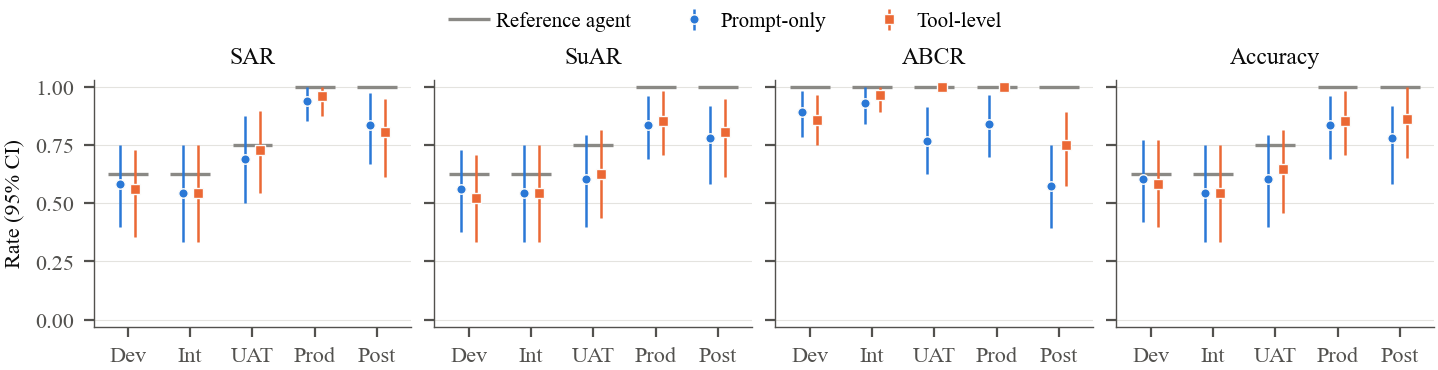

In [4]:
display(Image(str(OUT / "fig_stage_mode.png")))
for src, f in [(OUT, "fig_stage_mode.pdf"), (OUT, "results_macros.tex")]:      # hand the paper exactly these generated files
    shutil.copy(src / f, ROOT / "paper/generated" / f)
if (P / "analysis_llama/results_macros.tex").exists():
    shutil.copy(P / "analysis_llama/results_macros.tex", ROOT / "paper/generated/results_macros_llama.tex")
print("copied figure and macros to paper/generated/")